In [1]:
pip install gseapy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import gseapy as gp

# load both gene sets
shared_690 = pd.read_csv(r"C:\tri_disease_project\data\processed\shared_genes_protein_coding.csv")['hgnc_symbol'].tolist()
lcc_374 = pd.read_csv(r"C:\tri_disease_project\data\processed\lcc_gene_list.csv")['hgnc_symbol'].tolist()

print("Shared gene set (690):", len(shared_690))
print("LCC gene set (374):", len(lcc_374))

gene_sets_to_test = [
    'GO_Biological_Process_2023',
    'GO_Molecular_Function_2023',
    'GO_Cellular_Component_2023',
    'KEGG_2021_Human',
    'Reactome_2022'
]

def run_enrichment(gene_list, label, outdir):
    enr = gp.enrichr(
        gene_list=gene_list,
        gene_sets=gene_sets_to_test,
        organism='human',
        outdir=outdir,
        cutoff=0.05
    )
    results = enr.results
    results['gene_set_input'] = label
    return results

results_690 = run_enrichment(shared_690, 'shared_690', r"C:\tri_disease_project\results\tables\enrichr_shared690")
results_374 = run_enrichment(lcc_374, 'lcc_374', r"C:\tri_disease_project\results\tables\enrichr_lcc374")

print("\nShared 690 - total enriched terms (raw, before filtering):", len(results_690))
print("LCC 374 - total enriched terms (raw, before filtering):", len(results_374))

print("\nTop 10 results for shared_690:")
print(results_690.sort_values('Adjusted P-value').head(10)[['Gene_set', 'Term', 'Overlap', 'Adjusted P-value', 'Genes']])

print("\nTop 10 results for lcc_374:")
print(results_374.sort_values('Adjusted P-value').head(10)[['Gene_set', 'Term', 'Overlap', 'Adjusted P-value', 'Genes']])

results_690.to_csv(r"C:\tri_disease_project\results\tables\enrichment_shared690_full.csv", index=False)
results_374.to_csv(r"C:\tri_disease_project\results\tables\enrichment_lcc374_full.csv", index=False)

Shared gene set (690): 690
LCC gene set (374): 374

Shared 690 - total enriched terms (raw, before filtering): 5733
LCC 374 - total enriched terms (raw, before filtering): 4918

Top 10 results for shared_690:
                        Gene_set  \
0     GO_Biological_Process_2023   
4510               Reactome_2022   
1     GO_Biological_Process_2023   
2     GO_Biological_Process_2023   
3     GO_Biological_Process_2023   
4     GO_Biological_Process_2023   
4230             KEGG_2021_Human   
5     GO_Biological_Process_2023   
6     GO_Biological_Process_2023   
3351  GO_Molecular_Function_2023   

                                                   Term   Overlap  \
0     Regulation Of Transcription By RNA Polymerase ...  146/2028   
4510                   Signal Transduction R-HSA-162582  159/2465   
1     Regulation Of DNA-templated Transcription (GO:...  132/1922   
2     Positive Regulation Of Transcription By RNA Po...    82/938   
3     Positive Regulation Of DNA-templated Transc

In [3]:
keywords = ['insulin', 'renin', 'angiotensin', 'RAAS', 'adipokine', 'adipocytokine',
            'inflammat', 'oxidative stress', 'AMPK', 'PPAR', 'leptin', 'PI3K', 'FoxO']

def search_pathways(df, keywords, label):
    pattern = '|'.join(keywords)
    hits = df[df['Term'].str.contains(pattern, case=False, na=False)]
    print(f"\n=== {label}: matches for roadmap-predicted pathway keywords ===")
    print(hits[['Gene_set', 'Term', 'Overlap', 'Adjusted P-value']].sort_values('Adjusted P-value').to_string(index=False))
    return hits

hits_690 = search_pathways(results_690, keywords, "Shared 690")
hits_374 = search_pathways(results_374, keywords, "LCC 374")


=== Shared 690: matches for roadmap-predicted pathway keywords ===
                  Gene_set                                                                                                      Term Overlap  Adjusted P-value
           KEGG_2021_Human                                                                                           Renin secretion   17/69      1.787900e-08
           KEGG_2021_Human                                                                                PI3K-Akt signaling pathway  32/354      2.627738e-05
           KEGG_2021_Human                                                                                    AMPK signaling pathway  16/120      7.478958e-05
           KEGG_2021_Human                                                                                    FoxO signaling pathway  16/131      1.665736e-04
           KEGG_2021_Human                                                                                        Insulin resistance  14/

In [4]:
# generic/uninformative terms to exclude from the "headline" figure (still in full CSV for supplementary)
generic_terms = ['regulation of transcription', 'regulation of dna-templated transcription',
                  'regulation of cell population proliferation', 'transcription cis-regulatory',
                  'rna polymerase']

def filter_specific(df, generic_terms):
    pattern = '|'.join(generic_terms)
    return df[~df['Term'].str.contains(pattern, case=False, na=False)]

specific_690 = filter_specific(results_690, generic_terms).sort_values('Adjusted P-value')
specific_374 = filter_specific(results_374, generic_terms).sort_values('Adjusted P-value')

print("Top 20 specific/mechanistic terms — Shared 690:")
print(specific_690.head(20)[['Gene_set', 'Term', 'Overlap', 'Adjusted P-value']].to_string(index=False))

print("\nTop 20 specific/mechanistic terms — LCC 374:")
print(specific_374.head(20)[['Gene_set', 'Term', 'Overlap', 'Adjusted P-value']].to_string(index=False))

specific_690.to_csv(r"C:\tri_disease_project\results\tables\enrichment_shared690_specific_top.csv", index=False)
specific_374.to_csv(r"C:\tri_disease_project\results\tables\enrichment_lcc374_specific_top.csv", index=False)

Top 20 specific/mechanistic terms — Shared 690:
                  Gene_set                                                                     Term  Overlap  Adjusted P-value
             Reactome_2022                                         Signal Transduction R-HSA-162582 159/2465      1.589091e-12
           KEGG_2021_Human                                               cGMP-PKG signaling pathway   29/167      1.714546e-10
GO_Biological_Process_2023                               Regulation Of Gene Expression (GO:0010468)  84/1127      7.784942e-09
           KEGG_2021_Human                                                          Renin secretion    17/69      1.787900e-08
GO_Cellular_Component_2023                    Intracellular Membrane-Bounded Organelle (GO:0043231) 251/5175      1.040886e-07
GO_Cellular_Component_2023                                                     Nucleus (GO:0005634) 222/4487      1.819912e-07
GO_Molecular_Function_2023          3',5'-Cyclic-Nucleotide Pho

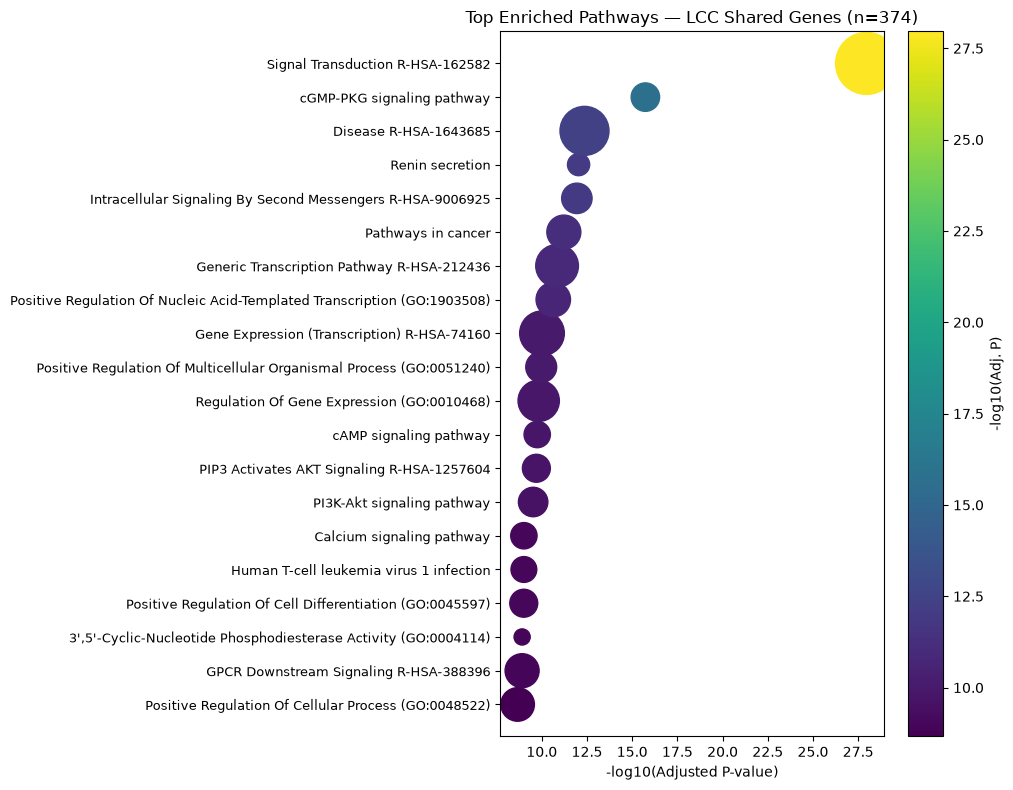

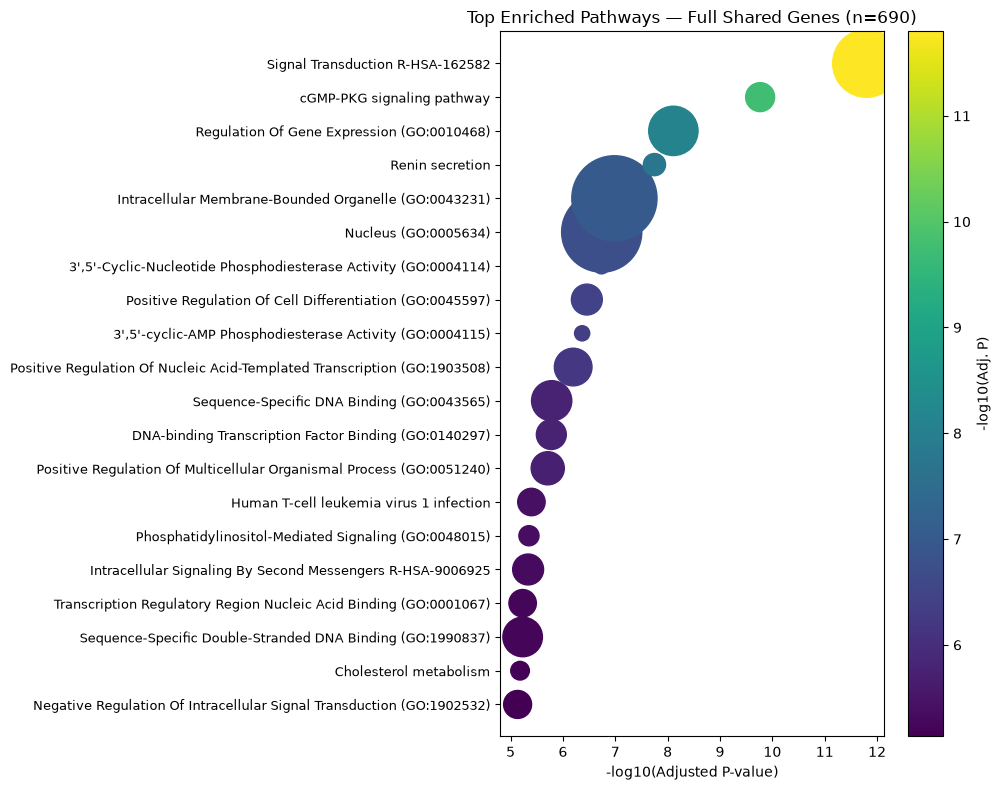

In [5]:
import matplotlib.pyplot as plt
import numpy as np

def plot_dotplot(df, title, filename, top_n=20):
    plot_df = df.head(top_n).copy()
    plot_df['neg_log_p'] = -np.log10(plot_df['Adjusted P-value'])
    plot_df['gene_count'] = plot_df['Overlap'].apply(lambda x: int(x.split('/')[0]))
    plot_df = plot_df.sort_values('neg_log_p')

    fig, ax = plt.subplots(figsize=(10, 8))
    scatter = ax.scatter(
        plot_df['neg_log_p'], range(len(plot_df)),
        s=plot_df['gene_count'] * 15,
        c=plot_df['neg_log_p'], cmap='viridis'
    )
    ax.set_yticks(range(len(plot_df)))
    ax.set_yticklabels(plot_df['Term'], fontsize=9)
    ax.set_xlabel('-log10(Adjusted P-value)')
    ax.set_title(title)
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('-log10(Adj. P)')
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

plot_dotplot(specific_374, "Top Enriched Pathways — LCC Shared Genes (n=374)",
             r"C:\tri_disease_project\results\figures\enrichment_dotplot_lcc374.png")

plot_dotplot(specific_690, "Top Enriched Pathways — Full Shared Genes (n=690)",
             r"C:\tri_disease_project\results\figures\enrichment_dotplot_shared690.png")